# 실험 3 시운전: 실기기에서 parameter-shift 1 step

목적: 실제 IBM 기기에서 두 방식의 1 step(회로 2N+1개)을 각각 job 하나로 돌려서 다음을 확인한다.
1. 큐비트 배치 — 기기에 3x3 격자가 그대로 들어가면 그 배치를 고정하고, 없으면(heavy-hex 기기) transpiler 자동 배치를 쓴다.
2. 시간 — job 하나의 벽시계 시간과 IBM이 집계한 사용 시간(usage).
3. 품질 — 측정 에너지와 기울기가 노이즈 없는 값과 얼마나 다른지(기울기 방향의 코사인 유사도, 1 step 뒤 AR).
4. 1 step 전후 비교 — 갱신 전 θ0과 갱신 뒤 θ1에서 기기 측정 에너지(SamplerV2 Z 기저 비트열 측정 및 대각 에너지 후처리), 비트열 표본 분포, 노이즈 없는 정확한 분포(상태벡터)를 나란히 본다.

- standard(`standard`): 전체 회로, 각도 114개 → 회로 229개. PADO(`pado_safe`): 증류 회로, 각도 61개 → 회로 123개.
- 결과는 `results_on_<기기>/extras/qpu_trial/<케이스>/`에 쓴다. 본 학습(`train_qpu.ipynb`)의 결과 폴더와 섞이지 않는다.
- shot 시간 하한 ≈ 회로 수 × shots × (rep_delay + 회로 길이). 예: 229 × 1024 × 161 µs ≈ 38초. IBM 사용량(usage)은 이보다 크다.
- 이 노트북은 `extras/qpu_trial/` 폴더에서 실행한다. 시작점 파일(`results_on_MI300X/.../start_points/`)이 먼저 있어야 한다.

## 설정

In [1]:
import json
import time
from pathlib import Path

import numpy as np
import rustworkx as rx
from qiskit import QuantumCircuit
from qiskit.circuit import ParameterVector
from qiskit.primitives import StatevectorEstimator
from qiskit.quantum_info import SparsePauliOp
from qiskit.transpiler import generate_preset_pass_manager
from qiskit_ibm_runtime import QiskitRuntimeService, SamplerV2

from common import device_tag, save_json   # extras/qpu_trial/common.py

# ---- 실행 설정 (보통 여기만 바꾼다)
DRY_RUN = False               # True: 실기기 대신 FAKE_BACKEND 스냅샷으로 이 컴퓨터에서 시뮬레이션 (코드 점검용, 사용량 0)
FAKE_BACKEND = "FakeNighthawk" # DRY_RUN용 스냅샷 (qiskit_ibm_runtime.fake_provider). heavy-hex 예: FakeFez, 정사각 격자: FakeNighthawk
IBM_BACKEND = "ibm_phoenix"   # 실기기 이름 (예: "ibm_phoenix", "ibm_miami"). 비우면 계정에서 쓸 수 있는 기기 중 대기열이 가장 짧은 것
RUNS = ["standard"]           # 돌릴 방식. "standard" = standard(전체 회로 229개) 1 step만, 둘 다 돌리려면 ["pado_safe", "standard"]
SHOTS = 512                   # 회로(행) 하나당 측정 횟수 (configs/TC3.json 기준 512; 필요시 1024 또는 256)
REP_DELAY = None              # 초. None이면 기기 기본값(ibm_phoenix는 1 µs). ibm_miami 최소값 강제 시 0.001
RESILIENCE_LEVEL = None       # SamplerV2 직접 비트열 측정 및 후처리 (오차 완화 미적용)
LR = 0.02                     # Adam 학습률 (본 학습과 같음)
SEED_TRANSPILER = 0
TWO_Q_GATE = "cz"             # 배치 점수에 쓸 2큐비트 게이트 (Heron, Nighthawk 계열은 cz)

REPO = Path.cwd().parents[1]          # 이 노트북은 extras/qpu_trial/ 폴더에서 실행한다
CASE = "grid3x3_inst0_seed120490"
START_DIR = REPO / f"results_on_{device_tag()}" / "TC3" / CASE / "start_points"

## API 키 (실기기에서만)

In [2]:
TOKEN = ""     # IBM Cloud API 키. 비우면 이 컴퓨터에 저장된 계정(~/.qiskit/qiskit-ibm.json)을 쓴다. 입력했으면 실행 뒤 지운다
INSTANCE = ""  # 인스턴스 CRN 또는 이름. 비우면 계정 기본값

## backend

In [3]:
if DRY_RUN:
    import importlib
    import warnings
    warnings.filterwarnings("ignore", message="Properties of fake_")
    service = None
    backend = getattr(importlib.import_module("qiskit_ibm_runtime.fake_provider"), FAKE_BACKEND)()
else:
    if TOKEN:
        service = QiskitRuntimeService(channel="ibm_quantum_platform", token=TOKEN, instance=INSTANCE or None)
    else:
        service = QiskitRuntimeService()                     # 저장된 계정
    backend = service.backend(IBM_BACKEND) if IBM_BACKEND else service.least_busy(operational=True, simulator=False)
    try:
        u = service.usage()
        print("usage(초):", {k: u.get(k) for k in ("usage_consumed_seconds", "usage_limit_seconds", "usage_remaining_seconds")})
    except Exception as e:
        print("usage 조회 불가:", e)

cfg = backend.configuration()
print(backend.name, backend.num_qubits, "qubits |", cfg.processor_type, "| 대기 job", backend.status().pending_jobs)
rep = REP_DELAY if REP_DELAY is not None else cfg.default_rep_delay
print(f"rep_delay: 기본 {cfg.default_rep_delay * 1e6:.0f} µs, 허용 {cfg.rep_delay_range[0] * 1e6:.0f}~{cfg.rep_delay_range[1] * 1e6:.0f} µs, 이번 설정 {rep * 1e6:.0f} µs")
if REP_DELAY is not None:
    assert cfg.rep_delay_range[0] <= REP_DELAY <= cfg.rep_delay_range[1], "REP_DELAY가 기기 허용 범위 밖"

OUT = REPO / f"results_on_{backend.name}" / "extras" / "qpu_trial" / CASE
OUT.mkdir(parents=True, exist_ok=True)
print("결과 폴더:", OUT.relative_to(REPO))

qiskit_runtime_service._discover_account:WARNING:2026-10-21 01:27:09,426: Loading account with the given token. A saved account will not be used.
qiskit_runtime_service.__init__:WARNING:2026-10-21 01:27:12,234: Instance was not set at service instantiation. Free and trial plan instances will be prioritized. Based on the following filters: (tags: None, region: us-east, eu-de), and available plans: (on-prem, premium), the available account instances are: P_QARS_Pusan_univ, QARS_Pusan_univ. If you need a specific instance set it explicitly either by using a saved account with a saved default instance or passing it in directly to QiskitRuntimeService(). Alternatively, pass instance='auto' or save it to your account for auto-selection without warning.
qiskit_runtime_service.backends:WARNING:2026-10-21 01:27:12,235: Using instance: P_QARS_Pusan_univ, plan: premium


usage(초): {'usage_consumed_seconds': 2397, 'usage_limit_seconds': 12000, 'usage_remaining_seconds': 9603}
ibm_phoenix 120 qubits | {'family': 'Nighthawk', 'revision': '2'} | 대기 job 259
rep_delay: 기본 1 µs, 허용 0~2000 µs, 이번 설정 1 µs
결과 폴더: results_on_ibm_phoenix/extras/qpu_trial/grid3x3_inst0_seed120490


## 1. 문제, 시작점, 회로

In [4]:
# 시작점 파일 두 개: circuit.json(게이트 목록), params.json(θ 값, brute force E_min/E_max, 무노이즈 에너지)
circ_json = json.loads((START_DIR / "circuit.json").read_text())
start = json.loads((START_DIR / "params.json").read_text())
n, e_min, e_max = circ_json["n_qubits"], start["e_min"], start["e_max"]
ar = lambda e: (e_max - e) / (e_max - e_min)   # approximation ratio: E_max이면 0, 바닥 상태 E_min이면 1

# 방식별 회로와 시작 θ. exact_only(standard): 전체 회로와 상수 초기값 / safe(PADO): 증류 뒤 남은 게이트와 사전학습·증류를 거친 θ
gates = {"standard": circ_json["gates"], "pado_safe": circ_json["pruned_gates"]}
theta0 = {"standard": np.array(start["theta_init"]), "pado_safe": np.array(start["theta_pado_safe_start"])}
e_start = {"standard": start["exact_energy"]["standard_start"], "pado_safe": start["exact_energy"]["pado_safe_start"]}

# 관측량 H = Σ J_ij Z_i Z_j + Σ h_i Z_i (전부 Z 기저 대각 항이므로 2^n개 비트열의 에너지를 미리 표로 만든다)
H = SparsePauliOp.from_sparse_list([("ZZ", [u, v], w) for u, v, w in circ_json["edges"]] +
                                   [("Z", [q], h) for q, h in circ_json["fields"]], num_qubits=n)
_idx = np.arange(1 << n, dtype=np.uint16)
_sz = np.array([1.0 - 2.0 * ((_idx >> q) & 1) for q in range(n)])   # 상태 인덱스 비트 q = (idx >> q) & 1: |0>→+1, |1>→−1
H_diag = np.zeros(1 << n)
for u, v, w in circ_json["edges"]:
    H_diag += w * _sz[u] * _sz[v]
for q, h in circ_json["fields"]:
    H_diag += h * _sz[q]
def sampler_evs_stds(pub_res):                                      # SamplerV2 결과(BitArray) → 행별 평균 에너지와 표준오차
    ba = pub_res.data.meas
    ints = (ba.array[..., 0].astype(np.uint16) << 8) | ba.array[..., 1].astype(np.uint16)
    e_shots = H_diag[ints]
    return e_shots.mean(axis=-1), e_shots.std(axis=-1, ddof=1) / np.sqrt(ba.num_shots)

circuits = {}
for run in RUNS:
    theta = ParameterVector("theta", len(theta0[run]))   # theta[i]의 번호 i = θ 배열의 자리
    qc = QuantumCircuit(n)
    for g in gates[run]:
        if g["gate"] == "H":
            qc.h(g["wires"][0])
        elif g["gate"] == "RZZ":                         # exp(-i θ ZZ / 2)
            qc.rzz(theta[g["param"]], *g["wires"])
        elif g["gate"] == "RZ":                          # exp(-i θ Z / 2)
            qc.rz(theta[g["param"]], g["wires"][0])
        elif g["gate"] == "RX":                          # exp(-i θ X / 2)
            qc.rx(theta[g["param"]], g["wires"][0])
    circuits[run] = qc
    # 확인: 노이즈 없는 Qiskit 에너지 == 시작점 파일의 에너지(PennyLane으로 계산)
    e = float(StatevectorEstimator().run([(qc, H, theta0[run])]).result()[0].data.evs)
    assert abs(e - e_start[run]) < 1e-8, (run, e, e_start[run])
    print(f"{run:10s} angles={len(theta0[run]):3d}  circuits/step={2 * len(theta0[run]) + 1:3d}  noiseless start AR={ar(e):.4f}")
print(f"brute force: E_min={e_min:.6f}, E_max={e_max:.6f}")

standard   angles=114  circuits/step=229  noiseless start AR=0.5291
brute force: E_min=-8.656307, E_max=9.354969


## 2. 큐비트 배치와 transpile

기기 연결 그래프 안에 3x3 격자(최근접 이웃 12쌍)가 그대로 들어가는 배치가 있으면 그중 오류 점수(2큐비트 게이트 오류 + 측정 오류의 합)가 가장 작은 것을 `initial_layout`으로 고정한다. heavy-hex 기기(Heron 계열)에는 그런 배치가 없어 transpiler 자동 배치를 쓴다. 어느 쪽이든 대각 이웃 결합(8쌍)은 직접 연결이 없어 SWAP이 들어간다.

In [5]:
# 논리 3x3 격자의 최근접 이웃 연결
grid = rx.PyGraph()
grid.add_nodes_from(range(n))
for i in range(3):
    for j in range(3):
        if j + 1 < 3:
            grid.add_edge(3 * i + j, 3 * i + j + 1, None)       # 오른쪽 이웃
        if i + 1 < 3:
            grid.add_edge(3 * i + j, 3 * (i + 1) + j, None)     # 아래쪽 이웃

coupling = backend.coupling_map.graph.to_undirected(multigraph=False)
twoq_err = backend.target[TWO_Q_GATE]
candidates = []
for mapping in rx.vf2_mapping(coupling, grid, subgraph=True, induced=False):   # {물리 큐비트: 논리 큐비트}
    layout = [0] * n
    for phys, logical in mapping.items():
        layout[logical] = phys
    score = 0.0
    for u, v in grid.edge_list():
        props = twoq_err.get((layout[u], layout[v])) or twoq_err.get((layout[v], layout[u]))
        score += props.error if props is not None and props.error is not None else 1.0
    for q in range(n):
        props = backend.target["measure"].get((layout[q],))
        score += props.error if props is not None and props.error is not None else 1.0
    candidates.append((score, layout))

if candidates:
    score, LAYOUT = min(candidates)
    print(f"3x3 격자 배치 {len(candidates)}개 중 오류 점수가 가장 작은 배치 (점수 {score:.4f}): {LAYOUT}")
else:
    LAYOUT = None
    print(f"{backend.name}에는 3x3 격자가 그대로 들어가는 배치가 없다 (heavy-hex). transpiler 자동 배치를 쓴다.")

pm = generate_preset_pass_manager(optimization_level=3, backend=backend, initial_layout=LAYOUT, seed_transpiler=SEED_TRANSPILER)
isa, phys = {}, {}
for run in RUNS:
    qc_m = circuits[run].copy()
    qc_m.measure_all()                                    # SamplerV2용 Z 기저 측정 추가
    isa[run] = pm.run(qc_m)                               # 기기용 회로 (파라미터는 비어 있음)
    phys[run] = isa[run].layout.initial_index_layout(filter_ancillas=True)
    if LAYOUT is not None:
        assert phys[run] == LAYOUT, (run, phys[run], LAYOUT)
    two_q = sum(1 for inst in isa[run].data if inst.operation.num_qubits == 2)
    dur = isa[run].estimate_duration(backend.target, unit="s")
    print(f"{run:10s} 2-qubit gates={two_q:3d}  depth={isa[run].depth():3d}  circuit duration={dur * 1e6:.1f} µs  "
          f"physical qubits={phys[run]}")
    print(f"           shot 시간 하한 ≈ {2 * len(theta0[run]) + 1} 회로 × {SHOTS} shots × {(rep + dur) * 1e6:.0f} µs"
          f" = {(2 * len(theta0[run]) + 1) * SHOTS * (rep + dur):.0f}초")

3x3 격자 배치 640개 중 오류 점수가 가장 작은 배치 (점수 0.0577): [81, 82, 83, 91, 92, 93, 101, 102, 103]
standard   2-qubit gates=156  depth=315  circuit duration=12.1 µs  physical qubits=[81, 82, 83, 91, 92, 93, 101, 102, 103]
           shot 시간 하한 ≈ 229 회로 × 512 shots × 13 µs = 2초


## 3. 1 step 실행 (Job 제출 → 상태 확인 → 결과 수집)

실기기 대기 중 노트북 셀이 멈춰 있지 않도록 3개 셀로 나눈다:
1. **3-1 (Job 제출)**: 방식마다 parameter-shift 회로 행렬 `(2N+1) × N`을 만들어 `sampler.run()`으로 제출만 하고 즉시 셀을 끝낸다.
2. **3-2 (Status 확인 / 비상 취소)**: 언제든 다시 실행해 현재 상태(`QUEUED` / `RUNNING` / `DONE`)와 경과 시간을 확인한다(비상 취소 코드 주석 포함).
3. **3-3 (결과 수집 및 1 step 갱신)**: `DONE` 확인 후 결과를 받아 기울기·Adam 1 step 업데이트·사용 시간(`usage_s`, 큐 대기·실행 시간)을 저장한다.

In [6]:
# [3-1] 하드웨어 Job 제출 (SamplerV2, 비동기 제출 후 바로 완료됨)
sampler = SamplerV2(mode=backend)              # job 모드 (오차 완화 없음, Z 기저 비트열 측정 후 H_diag로 후처리)
sampler.options.default_shots = SHOTS
if not DRY_RUN and REP_DELAY is not None:
    sampler.options.execution.rep_delay = REP_DELAY

jobs = {}
for run in RUNS:
    theta = theta0[run].copy()
    k = len(theta)
    rows = [theta.copy()]                                # 행 0: θ 그대로 → E(θ)
    for i in range(k):
        plus = theta.copy()
        plus[i] += np.pi / 2                             # 행 2i+1: θ_i만 +π/2 → E_i+
        minus = theta.copy()
        minus[i] -= np.pi / 2                            # 행 2i+2: θ_i만 −π/2 → E_i−
        rows += [plus, minus]
    rows = np.array(rows)                                # (2k+1) × k

    # 노이즈 없는 기준값: 같은 행렬을 상태벡터로
    evs_ref = np.asarray(StatevectorEstimator().run([(circuits[run], H, rows)]).result()[0].data.evs)
    grad_ref = (evs_ref[1::2] - evs_ref[2::2]) / 2

    t0 = time.perf_counter()
    job = sampler.run([(isa[run], rows)], shots=SHOTS)
    job_id = job.job_id()
    jobs[run] = {"job": job, "job_id": job_id, "t0": t0, "theta": theta, "rows": rows, "evs_ref": evs_ref, "grad_ref": grad_ref}
    print(f"[{run}] SamplerV2 job 제출 완료! job_id={job_id} (회로 {len(rows)}개 × {SHOTS} shots) → 아래 셀에서 status를 확인하세요.", flush=True)

[standard] SamplerV2 job 제출 완료! job_id=dbc19soc77vs738593v0 (회로 229개 × 512 shots) → 아래 셀에서 status를 확인하세요.


In [21]:
# [3-2] Job 상태(Status) 수시 확인 셀 (원할 때마다 반복 실행 가능)
for run, info in jobs.items():
    j = info["job"]
    elapsed = time.perf_counter() - info["t0"]
    st = j.status()
    st_name = st.name if hasattr(st, "name") else str(st)
    print(f"[{run}] job_id={info['job_id']} | status={st_name} | 제출 후 경과={elapsed:.1f}초")

# ---- [비상용] 제출한 job을 취소(Cancel)해야 할 때 아래 한 줄 주석을 풀고 실행하세요:
# for run, info in jobs.items(): info["job"].cancel(); print(f"[{run}] {info['job_id']} cancel 요청 완료")
# (특정 job_id 문자열로 직접 취소할 때: service.job("여기에_JOB_ID_입력").cancel())

[standard] job_id=dbc19soc77vs738593v0 | status=DONE | 제출 후 경과=11153.6초


In [22]:
# [3-3] 결과 수집 및 Adam 1 step 업데이트 (위 셀에서 status=DONE 확인 후 실행; 바로 실행하면 완료될 때까지 대기)
results = {}
for run, info in jobs.items():
    job = info["job"]
    job_id = info["job_id"]
    theta = info["theta"]
    rows = info["rows"]
    evs_ref = info["evs_ref"]
    grad_ref = info["grad_ref"]
    k = len(theta)

    res = job.result()[0]
    wall_s = time.perf_counter() - info["t0"]
    evs, stds = sampler_evs_stds(res)
    energy = float(evs[0])
    grad = (evs[1::2] - evs[2::2]) / 2
    cos = float(grad @ grad_ref / (np.linalg.norm(grad) * np.linalg.norm(grad_ref)))

    # Adam 첫 step 뒤 θ_1의 노이즈 없는 AR (측정 기울기로 간 경우 / 노이즈 없는 기울기로 간 경우)
    theta1 = theta - LR * grad / (np.abs(grad) + 1e-8)
    theta1_ref = theta - LR * grad_ref / (np.abs(grad_ref) + 1e-8)
    e1, e1_ref = (float(StatevectorEstimator().run([(circuits[run], H, th)]).result()[0].data.evs) for th in (theta1, theta1_ref))

    # IBM이 집계한 사용 시간(초)과 시각(큐 대기 시간 / 실행 시간 분리) 기록. 시뮬레이션(DRY_RUN)에는 없다
    usage_s, queue_s, exec_s, timestamps = None, None, None, {}
    try:
        usage_s = float(job.usage())
    except Exception:
        pass
    try:
        ts_raw = job.metrics().get("timestamps", {})
        timestamps = {k: str(v) for k, v in ts_raw.items()}   # datetime → 문자열
        import datetime as _dt
        to_dt = lambda x: x if hasattr(x, "timestamp") else _dt.datetime.fromisoformat(str(x).replace("Z", "+00:00"))
        if "created" in ts_raw and "running" in ts_raw:
            queue_s = (to_dt(ts_raw["running"]) - to_dt(ts_raw["created"])).total_seconds()
        if "running" in ts_raw and "finished" in ts_raw:
            exec_s = (to_dt(ts_raw["finished"]) - to_dt(ts_raw["running"])).total_seconds()
    except Exception:
        pass

    results[run] = {
        "run": run, "backend": backend.name, "dry_run": DRY_RUN, "job_id": job_id, "shots": SHOTS,
        "rep_delay_s": rep, "resilience_level": None if DRY_RUN else RESILIENCE_LEVEL,
        "physical_qubits": phys[run], "n_params": k, "n_circuits": int(len(rows)),
        "wall_s": wall_s, "queue_s": queue_s, "exec_s": exec_s, "usage_s": usage_s, "timestamps": timestamps,
        "energy": energy, "energy_std": float(stds[0]), "ar": ar(energy),
        "energy_noiseless": float(evs_ref[0]), "ar_noiseless": ar(float(evs_ref[0])),
        "grad": grad.tolist(), "grad_noiseless": grad_ref.tolist(), "grad_cosine": cos,
        "grad_norm_ratio": float(np.linalg.norm(grad) / np.linalg.norm(grad_ref)),
        "ar_after_1step_noiseless": ar(e1), "ar_after_1step_noiseless_if_exact_grad": ar(e1_ref),
        "theta0": theta.tolist(), "theta1": theta1.tolist(),
    }
    save_json(OUT / f"{run}.json", results[run])
    print(f"[{run}] 끝. 총 벽시계 {wall_s:.1f}초 (큐 대기 {f'{queue_s:.1f}' if queue_s is not None else '-'}초 + 실행 {f'{exec_s:.1f}' if exec_s is not None else '-'}초)"
          f" | 하드웨어 usage {usage_s}초, AR={ar(energy):.4f} (noiseless {ar(float(evs_ref[0])):.4f}), "
          f"grad cosine={cos:.3f}, 1 step 뒤 noiseless AR={ar(e1):.4f} (노이즈 없는 기울기였다면 {ar(e1_ref):.4f})", flush=True)

[standard] 끝. 총 벽시계 11162.7초 (큐 대기 8631.0초 + 실행 1106.2초) | 하드웨어 usage 6.0초, AR=0.5359 (noiseless 0.5291), grad cosine=0.638, 1 step 뒤 noiseless AR=0.5398 (노이즈 없는 기울기였다면 0.5471)


## 4. 1 step 전후의 에너지와 비트열 분포 (로컬 Qiskit Statevector 샘플링)

실기기 job을 추가로 쓰지 않고, 로컬 Qiskit `Statevector`로 `θ0`(1 step 전)과 `θ1`(1 step 후)의 비트열 표본(`SHOTS`개)과 정확한 확률 분포(512개 비트열 전부)를 계산해 에너지 분포·평균·바닥 상태 비율을 비교한다. 비트열 문자 q = 큐비트 q(전수 조사 파일의 `ground_state_bits`와 같은 규약).

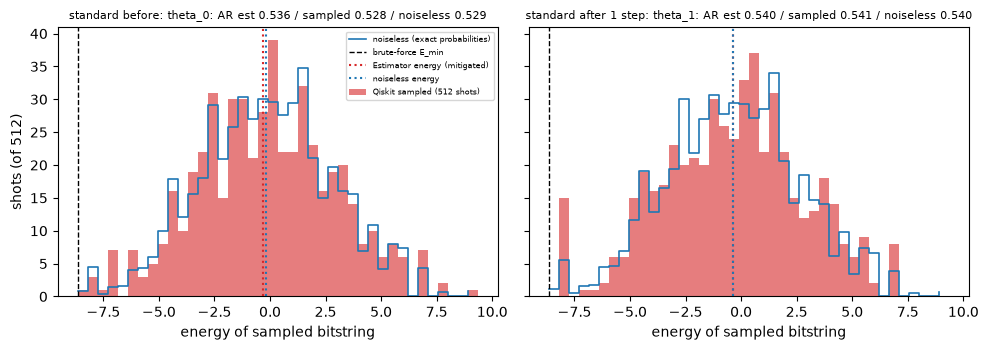

[standard] before E: estimator -0.2977 | sampled mean -0.1603 (std 3.126) | noiseless -0.1748 || P(ground): sampled 0.002 vs noiseless 0.002 | best sampled E -8.6563 (E_min -8.6563)
[standard] after  E: estimator -0.3675 | sampled mean -0.3885 (std 3.178) | noiseless -0.3675 || P(ground): sampled 0.000 vs noiseless 0.002 | best sampled E -8.1887 (E_min -8.6563)


In [23]:
from qiskit.quantum_info import Statevector
import matplotlib.pyplot as plt

prob = json.loads((START_DIR.parent / "problem.json").read_text())   # 문제 파일은 케이스 폴더에 하나
ground_str = "".join(str(b) for b in prob["ground_state_bits"])   # 바닥 상태 비트열, 문자 q = 큐비트 q (이 문제는 바닥 상태 1개)
U = np.array([u for u, v, w in circ_json["edges"]]); V = np.array([v for u, v, w in circ_json["edges"]])
W = np.array([w for u, v, w in circ_json["edges"]]); Q = np.array([q for q, h in circ_json["fields"]]); HF = np.array([h for q, h in circ_json["fields"]])
def energy_of_bits(bits):                                   # bits: (m, n) 0/1 배열 → 비트열마다 에너지. Z 고유값 |0>→+1, |1>→−1
    sz = 1 - 2 * bits
    return (sz[:, U] * sz[:, V]) @ W + sz[:, Q] @ HF
all_bits = (np.arange(2 ** n)[:, None] >> np.arange(n)) & 1  # 상태벡터 인덱스 i의 비트 q = (i >> q) & 1
E_all = energy_of_bits(all_bits)
bins = np.linspace(e_min, e_max, 41)

# 실기기 추가 job 없이 Qiskit Statevector로 θ0(갱신 전)과 θ1(실기기 기울기로 1 step 갱신 후)을 로컬 샘플링
for run in RUNS:
    d = results[run]
    theta, theta1 = np.array(d["theta0"]), np.array(d["theta1"])
    e1_noiseless = float(StatevectorEstimator().run([(circuits[run], H, theta1)]).result()[0].data.evs)

    cmp = {}
    for tag, th, e_est in (("before", theta, d["energy"]), ("after", theta1, e1_noiseless)):
        sv = Statevector(circuits[run].assign_parameters(th))
        sv.seed(SEED_TRANSPILER)
        counts = sv.sample_counts(SHOTS)
        keys = list(counts)
        bits = np.array([[int(ch) for ch in key[::-1]] for key in keys])   # Qiskit 문자열은 큐비트 0이 맨 오른쪽 → 뒤집어 문자 q = 큐비트 q
        cnt = np.array([counts[k] for k in keys], dtype=float)
        E_s = energy_of_bits(bits)
        p_exact = sv.probabilities()
        cmp[tag] = {
            "energy_estimator": e_est, "ar_estimator": ar(e_est),
            "energy_sampled_mean": float(E_s @ cnt / cnt.sum()), "energy_sampled_std": float(np.sqrt(((E_s - E_s @ cnt / cnt.sum()) ** 2) @ cnt / cnt.sum())),
            "ar_sampled": ar(float(E_s @ cnt / cnt.sum())), "best_energy_sampled": float(E_s.min()),
            "p_ground_sampled": counts.get(ground_str[::-1], 0) / cnt.sum(),             # Qiskit 키는 큐비트 0이 맨 오른쪽
            "energy_noiseless": float(E_all @ p_exact), "ar_noiseless": ar(float(E_all @ p_exact)),
            "p_ground_noiseless": float(p_exact[int(ground_str[::-1], 2)]),             # 상태벡터 인덱스: 큐비트 0이 최하위 비트
            "counts": {k[::-1]: int(v) for k, v in counts.items()},          # 저장은 문자 q = 큐비트 q 규약으로
            "hist_sampled": np.histogram(E_s, bins=bins, weights=cnt)[0].tolist(),
            "hist_noiseless": (np.histogram(E_all, bins=bins, weights=p_exact)[0] * cnt.sum()).tolist(),
        }
    d["before_after"] = {"estimator_job_id": None, "sampler_job_id": None, "usage_s_extra": 0.0,
                         "mode": "qiskit_statevector_sample", "bins": bins.tolist(), **cmp}
    save_json(OUT / f"{run}.json", d)

    # ---- 그림: Qiskit 로컬 표본 에너지 분포 vs 정확한 분포(노이즈 없음), 전/후
    fig, axes = plt.subplots(1, 2, figsize=(10, 3.6), sharey=True)
    for ax, tag, title in zip(axes, ("before", "after"), ("before: theta_0", "after 1 step: theta_1")):
        c = cmp[tag]
        ax.bar(bins[:-1], c["hist_sampled"], width=np.diff(bins), align="edge", color="tab:red", alpha=0.6, label=f"Qiskit sampled ({SHOTS} shots)")
        ax.step(bins[:-1], c["hist_noiseless"], where="post", color="tab:blue", linewidth=1.2, label="noiseless (exact probabilities)")
        ax.axvline(e_min, color="black", linestyle="--", linewidth=1, label="brute-force E_min")
        ax.axvline(c["energy_estimator"], color="tab:red", linestyle=":", linewidth=1.5, label="Estimator energy (mitigated)")
        ax.axvline(c["energy_noiseless"], color="tab:blue", linestyle=":", linewidth=1.5, label="noiseless energy")
        ax.set_title(f"{run} {title}: AR est {c['ar_estimator']:.3f} / sampled {c['ar_sampled']:.3f} / noiseless {c['ar_noiseless']:.3f}", fontsize=8)
        ax.set_xlabel("energy of sampled bitstring")
    axes[0].set_ylabel(f"shots (of {SHOTS})")
    axes[0].legend(fontsize=6)
    fig.tight_layout()
    fig.savefig(OUT / f"{run}_before_after.png", dpi=150)
    plt.show()
    for tag in ("before", "after"):
        c = cmp[tag]
        print(f"[{run}] {tag:6s} E: estimator {c['energy_estimator']:+.4f} | sampled mean {c['energy_sampled_mean']:+.4f} (std {c['energy_sampled_std']:.3f}) | noiseless {c['energy_noiseless']:+.4f}"
              f" || P(ground): sampled {c['p_ground_sampled']:.3f} vs noiseless {c['p_ground_noiseless']:.3f} | best sampled E {c['best_energy_sampled']:+.4f} (E_min {e_min:+.4f})")

## 5. 요약과 본 실행 환산

In [24]:
full_steps = {"pado_safe": 3, "standard": 12}     # 본 실행의 step 수 (configs/TC3.json과 같음)
print(f"{'방식':10s} {'회로':>5s} {'큐대기(초)':>10s} {'실행(초)':>9s} {'총벽시계':>8s} {'usage(초)':>10s} {'AR 측정':>8s} {'AR 무노이즈':>10s} {'grad cos':>9s} {'1 step 뒤 AR':>12s}")
total_proj = 0.0
for run, d in results.items():
    qs = f"{d['queue_s']:.1f}" if d.get("queue_s") is not None else "-"
    es = f"{d['exec_s']:.1f}" if d.get("exec_s") is not None else "-"
    us = f"{d['usage_s']:.1f}" if d.get("usage_s") is not None else "-"
    print(f"{run:10s} {d['n_circuits']:5d} {qs:>10s} {es:>9s} {d['wall_s']:8.1f} {us:>10s} "
          f"{d['ar']:8.4f} {d['ar_noiseless']:10.4f} {d['grad_cosine']:9.3f} {d['ar_after_1step_noiseless']:12.4f}")
    if d["usage_s"]:                                     # 시뮬레이션(DRY_RUN)에서는 0 또는 None이라 건너뛴다
        proj = full_steps[run] * d["usage_s"]            # 최종 에너지 확인 job(회로 1개)은 작아서 더하지 않음
        total_proj += proj
        print(f"           본 실행 환산 ({run}): {full_steps[run]} step × {d['usage_s']:.1f}초 ≈ {proj:.1f}초 (${proj * 1.60:,.0f})")
        if len(results) == 1 and run == "standard":
            pado_est_1step = d["usage_s"] * (123 / 229)
            pado_proj = full_steps["pado_safe"] * pado_est_1step
            total_proj += pado_proj
            print(f"           본 실행 환산 (pado_safe 추정, 123/229 비례): {full_steps['pado_safe']} step × {pado_est_1step:.1f}초 ≈ {pado_proj:.1f}초 (${pado_proj * 1.60:,.0f})")
if total_proj:
    print(f"두 방식 합계 환산 ≈ {total_proj:.1f}초 ({total_proj / 60:.1f}분, Pay-As-You-Go $1.60/초 기준 약 ${total_proj * 1.60:,.0f})")
    if service is not None:
        try:
            u = service.usage()
            print(f"계정 한도 {u.get('usage_limit_seconds')}초, 남은 {u.get('usage_remaining_seconds')}초")
        except Exception:
            pass
if any("before_after" in d for d in results.values()):
    print()
    print(f"{'방식':10s} {'구간':7s} {'E 기기(est)':>12s} {'E 기기(표본)':>12s} {'E 무노이즈':>10s} {'P(바닥) 기기':>12s} {'P(바닥) 무노이즈':>14s}")
    for run, d in results.items():
        if "before_after" not in d:
            continue
        for tag in ("before", "after"):
            c = d["before_after"][tag]
            print(f"{run:10s} {tag:7s} {c['energy_estimator']:12.4f} {c['energy_sampled_mean']:12.4f} {c['energy_noiseless']:10.4f} "
                  f"{c['p_ground_sampled']:12.3f} {c['p_ground_noiseless']:14.3f}")
save_json(OUT / "summary.json", {"backend": backend.name, "shots": SHOTS, "rep_delay_s": rep, "runs": results})
print("saved", OUT.relative_to(REPO))

방식            회로     큐대기(초)     실행(초)     총벽시계   usage(초)    AR 측정    AR 무노이즈  grad cos  1 step 뒤 AR
standard     229     8631.0    1106.2  11162.7        6.0   0.5359     0.5291     0.638       0.5398
           본 실행 환산 (standard): 10 step × 6.0초 ≈ 60.0초 ($96)
           본 실행 환산 (pado_safe 추정, 123/229 비례): 3 step × 3.2초 ≈ 9.7초 ($15)
두 방식 합계 환산 ≈ 69.7초 (1.2분, Pay-As-You-Go $1.60/초 기준 약 $111)
계정 한도 12000초, 남은 9597초

방식         구간         E 기기(est)     E 기기(표본)     E 무노이즈     P(바닥) 기기     P(바닥) 무노이즈
standard   before       -0.2977      -0.1603    -0.1748        0.002          0.002
standard   after        -0.3675      -0.3885    -0.3675        0.000          0.002
saved results_on_ibm_phoenix/extras/qpu_trial/grid3x3_inst0_seed120490
